# 04 · Cross-architecture results — figures and tables, YOLO26-seg vs. U-Net vs. SAM 3 (ISIC 2018 Task 1)

> **For the manuscript use `~/projects/sandbox_models_analysis/notebooks/04_master_cross_model_comparison.ipynb`** (the paper
> workspace); this repository notebook remains the per-repository cross-architecture view.

Master analysis notebook for the thesis. Apart from section 0 (Phase 1 masks side by side, available as soon as the
masks are exported), it reads **only** the Phase 5 outputs of the three 5-phase pipelines and produces the
cross-architecture tables (LaTeX + CSV), the paired statistics and the figures. **No training, no GPU, no
re-evaluation** — run it after `run_pipeline*.sh --phases 5` has finished in the three repositories and the
`logs/<pipeline>/` folders are on this machine.

| Output | Content |
|---|---|
| Table 1 | Test accuracy (DSC, JSI, ISIC JSI$_{0.65}$, Boundary IoU, NSD, HD95) with bootstrap 95 % CI |
| Table 2 | Batch-1 efficiency: params, GFLOPs, median / P95 latency, FPS, peak VRAM, real-time criterion |
| Table 3 | Effect of HPO (Optimized − Baseline, paired) for every model |
| Table 4 | FP16 vs. FP32: accuracy cost and speed-up |
| Table 5 | Training cost per phase (GPU hours) |
| Table 6 | Phase 2 cross-validation vs. test (generalisation check) |
| Table 7 | Paired cross-architecture tests on per-image DSC (all pairs, Holm-adjusted) |
| Figure 1 | Accuracy (DSC, JSI) vs. latency, FPS and parameters, with the Pareto front |
| Figure 2 | Training time and inference time (median → P95) with the real-time budget |
| Figure 3 | Per-image score distributions |
| Figure 4 | Pairwise ΔDSC matrix with Holm-adjusted significance |
| Figure 5 | Boundary metrics (Boundary IoU, NSD, HD95) with 95 % CI |
| Figure 6 | Peak VRAM (model allocator vs. whole process incl. CUDA context) |

**Where things are.** This notebook and `results_aggregator.py` live in the folder that contains the three
repositories (`sandbox_yolo26/`, `sandbox_unet/`, `sandbox_sam3/`; any letter case), or in `<repo>/analysis/`. The
pipelines are found automatically under `<repo>/logs/<PIPELINE_NAME>/`; override with `$YOLO26_PIPELINE_DIR`,
`$UNET_PIPELINE_DIR`, `$SAM3_PIPELINE_DIR`. Everything is written to `<root>/sandbox_models_analysis/exports/repo_notebook_04/`
(`tables/*.tex|csv`, `figures/*.pdf|png`, `data/*.csv`). The same outputs can be produced headless with
`python results_aggregator.py`.

**LaTeX.** Tables use `booktabs` and `\resizebox` → `\usepackage{booktabs,graphicx}`; include with `\input{...}`.

**Requirements.** `numpy`, `pandas`, `scipy`, `matplotlib` (no deep-learning stack).

In [1]:
# ---- Configuration ----------------------------------------------------------
PIPELINE_NAME = "pipeline_final_v1"   # logs/<PIPELINE_NAME>/ in every repository
DEPLOY_VARIANT = "optimized"          # variant compared across architectures ("optimized" = Phase 4, chosen a priori)
PRECISION = "fp32"                    # primary precision (training was FP32); FP16 is in Table 4
REALTIME_FPS = 30                     # real-time criterion: end-to-end P95 latency <= 1000 / REALTIME_FPS ms
N_BOOT = 2000                         # bootstrap resamples (paired CIs), seeded
ROOT = None                           # folder holding the three repositories; None = auto-discover

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import results_aggregator as agg  # noqa: E402  (next to this notebook)

pd.set_option("display.max_columns", 40, "display.width", 200)
agg.setup_style()
PHASE5_MISSING = "⚠️ Phase 5 results not yet generated. Training is likely still in progress. Skipping cell execution."
try:
    art = agg.build(ROOT, PIPELINE_NAME, DEPLOY_VARIANT, PRECISION, REALTIME_FPS, n_boot=N_BOOT)
except FileNotFoundError as err:   # no pipeline has written its Phase 5 summary yet
    art, missing_reason = None, str(err)
PHASE5_READY = art is not None
if not PHASE5_READY:
    print(PHASE5_MISSING)
    print("[info]", missing_reason)
else:
    written = agg.write_tables(art)
    print("root     :", art.root)
    for k, p in art.pipes.items():
        print(f"pipeline : {agg.ARCH_BY_KEY[k].label:<11} {p.root}")
    print("outputs  :", art.out)
    print(f"systems  : {list(art.sel.system)}  ({DEPLOY_VARIANT}, {PRECISION})")
    print(f"tables   : {len(written)} written to {art.out / 'tables'}")
    for w in art.warnings:
        print("WARNING  :", w)

root     : /home/antoniovinicius/projects
pipeline : YOLO26-seg  /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1
pipeline : U-Net       /home/antoniovinicius/projects/sandbox_unet/logs/pipeline_final_v1
pipeline : SAM 3       /home/antoniovinicius/projects/sandbox_sam3/logs/pipeline_final_v1
outputs  : /home/antoniovinicius/projects/sandbox_models_analysis/exports/repo_notebook_04
systems  : ['YOLO26-n', 'YOLO26-s', 'YOLO26-m', 'YOLO26-l', 'YOLO26-x', 'U-Net', 'SAM 3']  (optimized, fp32)
tables   : 7 written to /home/antoniovinicius/projects/sandbox_models_analysis/exports/repo_notebook_04/tables


## 0. Phase 1 side by side — U-Net vs. YOLO26-nano vs. SAM 3 (official validation split)

Original image, ground truth and the Phase 1 (Baseline) mask of each model on the same validation images: 3 random
images and the 3 with the largest JSI spread between the models. Each model's mask is produced by its own pipeline
rule (U-Net: probability map upsampled, threshold 0.5; YOLO26 and SAM 3: top-1 instance, `PIXEL_CONF`) and scored
with the shared `segmentation_metrics`. **Independent of Phase 5** — it needs only the exported masks:

```bash
cd ~/projects    # CPU only (no --gpus): never competes with a training run
docker run --rm --cpus 8 --user $(id -u):$(id -g) -e HOME=/tmp -v $PWD/sandbox_unet/unet:/workspace/unet:ro \
  -v $PWD/sandbox_unet/datasets:/workspace/datasets:ro -v $PWD/sandbox_unet/logs:/workspace/logs \
  -v $PWD/sandbox_yolo26/datasets/isic2018_task1_official:/workspace/yolo26_dataset:ro \
  -w /workspace/unet --entrypoint python unet_ft export_phase1_val_masks.py
docker run --rm --cpus 8 --user $(id -u):$(id -g) -e HOME=/tmp -e YOLO_CONFIG_DIR=/tmp \
  -v $PWD/sandbox_yolo26/yolo26_seg:/workspace/yolo26_seg:ro -v $PWD/sandbox_yolo26/datasets:/workspace/datasets:ro \
  -v $PWD/sandbox_yolo26/logs:/workspace/logs -w /workspace/yolo26_seg --entrypoint python yolo26_ft \
  export_phase1_val_masks.py --models nano
docker run --rm --cpus 8 --user $(id -u):$(id -g) -e HOME=/tmp -v $PWD/sandbox_sam3/sam3_seg:/workspace/sam3_seg:ro \
  -v $PWD/sandbox_sam3/sam3:/workspace/sam3:ro -v $PWD/sandbox_sam3/datasets:/workspace/datasets:ro \
  -v $PWD/sandbox_sam3/logs:/workspace/logs -w /workspace/sam3_seg -e PYTHONPATH=/workspace \
  --entrypoint python sam3_ft export_phase1_val_masks.py --source dump
```

SAM 3 `--source dump` (CPU) uses the predictions of its **last** validation epoch, labelled with that epoch in the
figure; once a GPU is free, `--source best` (add `--gpus device=N`) exports the selected checkpoint instead.
Saved as `<folder holding the repositories>/sandbox_models_analysis/exports/repo_notebook_04/figures/fig0_phase1_side_by_side.pdf|png`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


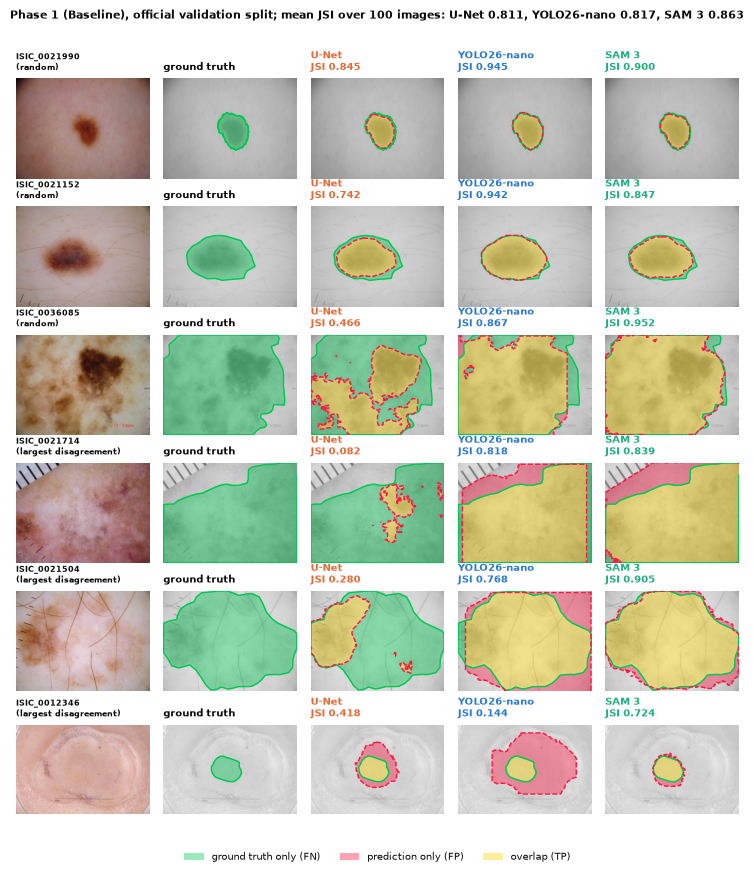

U-Net                  Phase 1 best.pt
YOLO26-nano            Phase 1 best.pt
SAM 3                  Phase 1 best.pt (epoch 7)
saved: /home/antoniovinicius/projects/sandbox_models_analysis/exports/repo_notebook_04/figures/fig0_phase1_side_by_side.pdf|png


In [2]:
# Independent of Phase 5: reads <repo>/logs/<PIPELINE_NAME>/phase1_val_masks/ of each repository
phase1_root = agg.discover_root(ROOT)
fig = agg.fig_phase1_side_by_side(phase1_root, PIPELINE_NAME, n_random=3, n_disagree=3,
                                  save=agg.save_to(phase1_root / "sandbox_models_analysis" / "exports" / "repo_notebook_04" / "figures"))
if fig is None:
    print("⚠️ Phase 1 validation masks not yet exported. Skipping the side-by-side figure "
          "(run export_phase1_val_masks.py in each repository, commands above).")
else:
    plt.show()
    for s in agg.phase1_masks(phase1_root, PIPELINE_NAME):
        print(f"{s['label']:<22} {s['meta'].get('source', '')}")
    print("saved:", phase1_root / "sandbox_models_analysis" / "exports" / "repo_notebook_04" / "figures" / "fig0_phase1_side_by_side.pdf|png")

## Pipeline notes to disclose

Protocol deviations recorded by the pipelines themselves (`protocol_notes` and `warnings` of every
`summary/final_results.json`). Everything printed here belongs in the Methods or Limitations section.

In [3]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    for k, p in art.pipes.items():
        for n in p.report.get("protocol_notes", []):
            print(f"[{agg.ARCH_BY_KEY[k].label}] NOTE: {n}")
    contended = [s for s, c in zip(art.sel.system, art.sel.get("contended", [None] * len(art.sel))) if pd.notna(c) and bool(c)]
    print("contended benchmarks (re-run Phase 5b on an idle GPU before quoting):", contended or "none")

[SAM 3] NOTE: Training budget 30 epochs / patience 30 (YOLO26, U-Net: 120 / 120), i.e. no early stopping: training uses FP16 AMP, a frozen text encoder and no activation checkpointing in the backbones (the former FP32 setup took ~1.9 h per epoch on a V100S).
[SAM 3] NOTE: HPO 10 trials x 10 epochs, patience 10 (YOLO26, U-Net: 30 x 30), Optuna TPE with 5 start-up trials.
[SAM 3] NOTE: Determinism: seeds, cuDNN deterministic, deterministic grid_sample, warn-only deterministic algorithms; the ViT memory-efficient attention backward stays nondeterministic, so repeated or resumed runs are statistically equivalent, not bit-identical. The quantified bound (<= ~7e-5 in the weights after 3 epochs, 5th digit of val JSI) and the strict-mode cost (+33 % time) were measured with the earlier FP32 setup; they were not re-measured with FP16 AMP.
[SAM 3] NOTE: FP16 = torch.autocast(float16) with FP32 weights (SAM 3's official mixed-precision path).
[SAM 3] NOTE: Prompt 'skin lesion', input 1008 px, pre

## Table 1 — Test-set accuracy

Per-image mean over the 1,000 official test images with the seeded bootstrap 95 % CI written by each pipeline's
Phase 5a (identical metric code in the three repositories: `segmentation_metrics.py`). Best value per column in
bold in the LaTeX file. HD95 is in pixels at the dataset resolution (longer side ≤ 1,024 px); a missed lesion scores
the image diagonal (Metrics Reloaded: penalise, never drop).

In [4]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.tables["accuracy"])

,System,DSC,JSI,JSI$_{0.65}$,Boundary IoU,NSD,HD95 (px),Missed
0,YOLO26-n,"0.812 [0.797, 0.826]","0.735 [0.719, 0.750]","0.662 [0.638, 0.684]","0.302 [0.288, 0.316]","0.479 [0.458, 0.501]","116.8 [107.9, 126.3]",0
1,YOLO26-s,"0.875 [0.865, 0.883]","0.798 [0.787, 0.808]","0.742 [0.724, 0.761]","0.297 [0.283, 0.311]","0.469 [0.448, 0.489]","67.1 [60.4, 74.6]",3
2,YOLO26-m,"0.873 [0.864, 0.881]","0.794 [0.783, 0.804]","0.730 [0.711, 0.748]","0.282 [0.268, 0.295]","0.446 [0.424, 0.466]","65.0 [60.1, 70.2]",0
3,YOLO26-l,"0.882 [0.874, 0.890]","0.806 [0.796, 0.816]","0.754 [0.736, 0.771]","0.303 [0.290, 0.316]","0.481 [0.461, 0.501]","63.1 [58.3, 68.4]",0
4,YOLO26-x,"0.877 [0.867, 0.886]","0.804 [0.793, 0.815]","0.749 [0.730, 0.766]","0.344 [0.331, 0.356]","0.543 [0.525, 0.561]","71.5 [65.6, 78.2]",0
5,U-Net,"0.871 [0.861, 0.880]","0.795 [0.783, 0.806]","0.723 [0.703, 0.743]","0.358 [0.344, 0.371]","0.561 [0.543, 0.580]","89.6 [82.7, 96.9]",2
6,SAM 3,"0.910 [0.902, 0.916]","0.849 [0.840, 0.857]","0.817 [0.802, 0.831]","0.423 [0.410, 0.436]","0.652 [0.634, 0.669]","53.3 [48.2, 58.7]",0


## Table 2 — Efficiency at batch = 1 and the real-time criterion

Forward = network only (CUDA events); end-to-end = decoded image in host memory → binary mask at dataset resolution
in host memory (the mask that is scored), P95 over 100 distinct test images. VRAM: PyTorch allocator peak (the
model) and the driver-level process peak (CUDA context and allocator cache included — what a device must provide).
GFLOPs at each model's native input: YOLO26 640 px, U-Net 256 px, SAM 3 1008 px (thop for the CNNs,
`FlopCounterMode` for SAM 3, which counts the attention products thop cannot see).

In [5]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.tables["efficiency"])

,System,Params (M),GFLOPs,Input (px),Fwd median (ms),Fwd P95 (ms),FPS (fwd),E2E median (ms),E2E P95 (ms),FPS (E2E),VRAM alloc. (MB),VRAM process (MB),Real-time (30 FPS)
0,YOLO26-n,2.7,9.0,640,8.26,8.85,120.0,12.45,12.69,79.8,74,774,yes
1,YOLO26-s,10.4,34.0,640,8.78,9.18,112.9,11.60,12.40,85.0,129,658,yes
2,YOLO26-m,23.5,121.2,640,12.54,12.68,79.8,13.30,14.13,73.0,232,794,yes
3,YOLO26-l,27.9,139.4,640,14.94,15.47,66.6,16.61,18.91,59.2,249,842,yes
4,YOLO26-x,62.7,313.0,640,27.17,27.41,36.8,24.55,24.59,40.7,439,"1,324",yes
5,U-Net,2.2,6.4,256,1.53,1.63,642.3,4.80,4.89,205.7,35,424,yes
6,SAM 3,840.5,"6,057","1,008",600.85,603.50,1.7,607.15,609.67,1.6,"4,106","5,460",no


## Figure 1 — Accuracy vs. efficiency

The central figure of the "lightweight vs. foundation model" argument: test DSC and JSI (95 % CI) against the measured
latency, throughput and parameter count. One colour per architecture; YOLO26 sizes are joined n → x; the dotted line
is the Pareto front (no other model is both faster/smaller and more accurate).

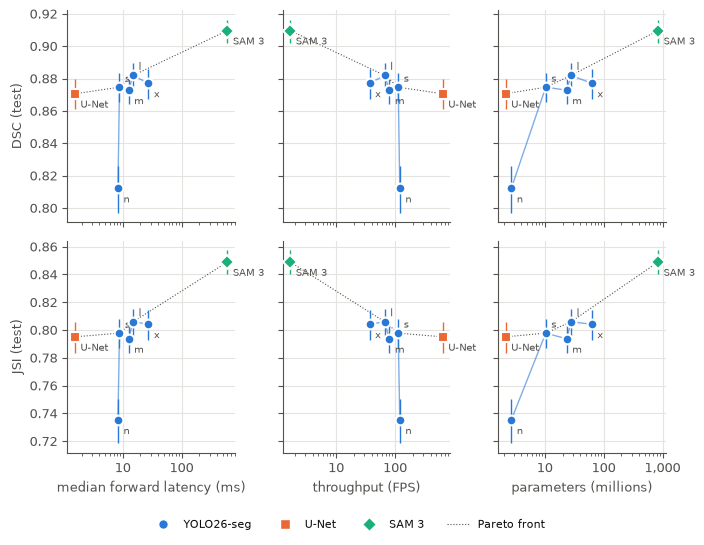

,system,arch_label,dsc_mean,dsc_ci95_low,dsc_ci95_high,jsi_mean,jsi_ci95_low,jsi_ci95_high,jsi_thr_mean,jsi_thr_ci95_low,jsi_thr_ci95_high,biou_mean,biou_ci95_low,biou_ci95_high,nsd_mean,nsd_ci95_low,nsd_ci95_high,hd95_mean,hd95_ci95_low,hd95_ci95_high,n_images,n_empty_pred,params_M,gflops,input_px,fwd_median_ms,fwd_p95_ms,fwd_fps,e2e_median_ms,e2e_p95_rt_ms,e2e_fps,vram_peak_allocated_mb,vram_process_peak_mb,realtime_30fps
0,YOLO26-n,YOLO26-seg,0.8121,0.7972,0.8261,0.7352,0.7185,0.7504,0.6618,0.6377,0.6836,0.3019,0.2878,0.3160,0.4795,0.4582,0.5006,116.8343,107.9259,126.3487,1000,0,2.6891,8.9572,640,8.2616,8.8520,119.9835,12.4525,12.6852,79.7932,73.6958,774.0,True
1,YOLO26-s,YOLO26-seg,0.8747,0.8653,0.8833,0.7978,0.7868,0.8082,0.7421,0.7238,0.7605,0.2966,0.2832,0.3110,0.4685,0.4482,0.4895,67.1041,60.4065,74.6456,1000,3,10.3657,34.0465,640,8.7792,9.1821,112.9198,11.6016,12.4042,84.9685,129.1377,658.0,True
2,YOLO26-m,YOLO26-seg,0.8728,0.8642,0.8809,0.7937,0.7833,0.8036,0.7302,0.7109,0.7482,0.2821,0.2684,0.2954,0.4455,0.4242,0.4664,65.0077,60.0972,70.1635,1000,0,23.5082,121.1593,640,12.5368,12.6822,79.7501,13.2996,14.1291,72.9946,232.3931,794.0,True
3,YOLO26-l,YOLO26-seg,0.8819,0.8739,0.8897,0.8059,0.7960,0.8155,0.7541,0.7364,0.7706,0.3028,0.2901,0.3161,0.4812,0.4614,0.5012,63.1401,58.3266,68.4291,1000,0,27.9045,139.4066,640,14.9381,15.4700,66.6140,16.6079,18.9149,59.1664,249.1689,842.0,True
4,YOLO26-x,YOLO26-seg,0.8771,0.8673,0.8856,0.8042,0.7929,0.8145,0.7485,0.7302,0.7661,0.3436,0.3307,0.3564,0.5434,0.5250,0.5614,71.5140,65.6139,78.1899,1000,0,62.7279,312.9829,640,27.1688,27.4132,36.7853,24.5531,24.5904,40.7128,439.0493,1324.0,True
5,U-Net,U-Net,0.8706,0.8609,0.8796,0.7951,0.7834,0.8060,0.7234,0.7029,0.7431,0.3581,0.3445,0.3713,0.5614,0.5427,0.5799,89.5788,82.6953,96.8813,1000,2,2.1587,6.4005,256,1.5319,1.6345,642.3313,4.7955,4.8886,205.6582,34.9067,424.0,True
6,SAM 3,SAM 3,0.9096,0.9021,0.9163,0.8490,0.8403,0.8574,0.8165,0.8022,0.8310,0.4228,0.4097,0.4363,0.6517,0.6343,0.6691,53.2740,48.1963,58.6690,1000,0,840.5098,6057.1904,1008,600.8525,603.5017,1.6644,607.1530,609.6720,1.6471,4105.5283,5460.0,False


In [6]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig = agg.fig_accuracy_vs_efficiency(art.sel, metrics=("dsc", "jsi"), save=art.save_fig)
    plt.show()
    display(art.tables["accuracy_numeric"].merge(art.tables["efficiency_numeric"], on=["system", "arch_label"]).round(4))

## Figure 2 — Training and inference time

(a) GPU hours of the whole 5-phase protocol (Phases 1–4) and of the final model alone (Phase 4). (b) Median batch-1
latency with a line to its P95, forward vs. end-to-end and FP32 vs. FP16, against the real-time budget.

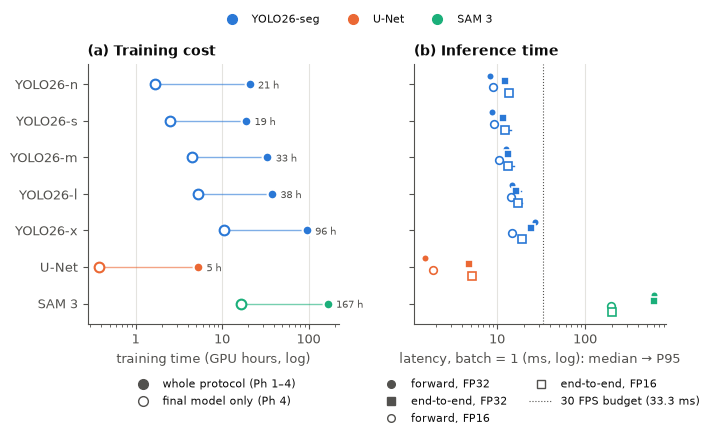

,System,arch,Ph 1 baseline (h),Ph 2 CV (5 folds) (h),Ph 3 HPO (h),Ph 4 optimized (h),Total (h),Epochs (Ph 1),s / epoch (Ph 1)
0,YOLO26-n,yolo26,1.70,9.09,8.37,1.68,20.84,120,51.07
1,YOLO26-s,yolo26,2.50,11.55,2.50,2.47,19.03,120,75.11
2,YOLO26-m,yolo26,4.52,19.95,4.53,4.50,33.50,120,135.56
3,YOLO26-l,yolo26,5.28,24.65,2.65,5.27,37.86,120,158.51
4,YOLO26-x,yolo26,10.50,45.63,28.90,10.47,95.50,120,315.15
5,U-Net,unet,0.38,1.70,2.83,0.38,5.29,120,11.34
6,SAM 3,sam3,16.77,77.57,55.80,16.76,166.89,30,2012.55


In [7]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig = agg.fig_training_inference_time(art.sel, art.tables["training"], REALTIME_FPS, save=art.save_fig)
    plt.show()
    display(art.tables["training"].round(2))

## Figure 3 — Per-image distributions

Box = IQR, centre line = median, whiskers = P5–P95, ◆ = mean. The mean (the reported figure) and the tails
(failures) can tell different stories — read with Table 1's "Missed" column.

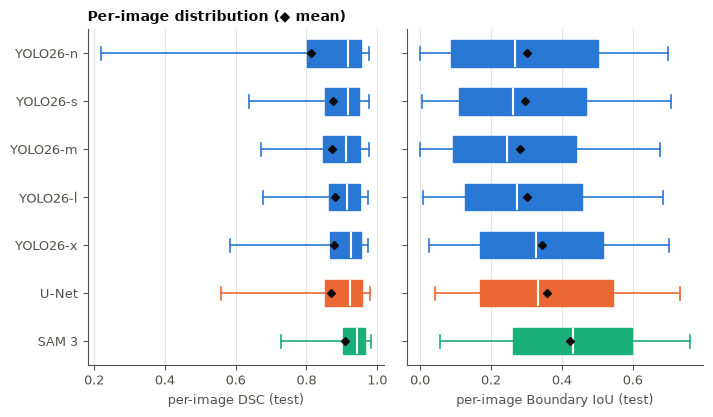

In [8]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig = agg.fig_per_image_distributions(art.sel, art.per_image, save=art.save_fig)
    plt.show()

## Paired statistics across architectures

All systems are scored on the **same** 1,000 test images, so comparisons are paired by ISIC ID. Omnibus: Friedman
test per metric (Kendall's W = effect size; mean rank 1 = best). Pairs: mean difference with a seeded paired
bootstrap 95 % CI, two-sided Wilcoxon signed-rank test, matched-pairs rank-biserial r, and Holm-adjusted p-values
within each metric (all pairs = one family). Report the CI of the difference, not only the p-value: with
n = 1,000, clinically negligible differences can be "significant".

In [9]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.friedman.round(4))

,metric,n_images,k_systems,chi2,p,kendall_w,mean_rank[YOLO26-n],mean_rank[YOLO26-s],mean_rank[YOLO26-m],mean_rank[YOLO26-l],mean_rank[YOLO26-x],mean_rank[U-Net],mean_rank[SAM 3]
0,dsc,1000,7,511.3314,0.0,0.0852,4.4660,4.3445,4.4210,4.2480,4.013,3.8440,2.6635
1,jsi,1000,7,511.3314,0.0,0.0852,4.4660,4.3445,4.4210,4.2480,4.013,3.8440,2.6635
2,biou,1000,7,615.2846,0.0,0.1025,4.4425,4.4380,4.6025,4.3315,3.900,3.6495,2.6360
3,nsd,1000,7,563.0782,0.0,0.0938,4.4130,4.4110,4.5470,4.2960,3.959,3.6930,2.6810
4,hd95,1000,7,444.1901,0.0,0.0740,4.5030,4.2035,4.1550,4.1515,4.175,4.1095,2.7025


In [10]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
elif art.tests.empty:
    print("⚠️ Paired cross-architecture tests need Phase 5 results from at least two architectures. Skipping cell execution.")
else:
    display(agg.pairwise_table(art.tests, "dsc"))

,A,B,n,ΔDSC (A−B) [95% CI],r (rank-biserial),A better / B better,p (Wilcoxon),p (Holm)
0,YOLO26-n,YOLO26-s,1000,"-0.0626 [-0.0760, -0.0492]",-0.16,485 / 514,<0.001,<0.001
1,YOLO26-n,YOLO26-m,1000,"-0.0607 [-0.0733, -0.0489]",-0.15,486 / 513,<0.001,<0.001
2,YOLO26-n,YOLO26-l,1000,"-0.0698 [-0.0827, -0.0575]",-0.18,482 / 517,<0.001,<0.001
3,YOLO26-n,YOLO26-x,1000,"-0.0650 [-0.0789, -0.0510]",-0.25,442 / 557,<0.001,<0.001
4,YOLO26-n,U-Net,1000,"-0.0585 [-0.0720, -0.0453]",-0.29,388 / 612,<0.001,<0.001
5,YOLO26-n,SAM 3,1000,"-0.0975 [-0.1120, -0.0839]",-0.62,249 / 751,<0.001,<0.001
6,YOLO26-s,YOLO26-m,1000,"0.0018 [-0.0048, 0.0084]",+0.05,521 / 478,0.134,0.386
7,YOLO26-s,YOLO26-l,1000,"-0.0073 [-0.0137, -0.0011]",-0.06,486 / 513,0.113,0.386
8,YOLO26-s,YOLO26-x,1000,"-0.0024 [-0.0100, 0.0054]",-0.20,432 / 567,<0.001,<0.001
9,YOLO26-s,U-Net,1000,"0.0040 [-0.0040, 0.0124]",-0.10,442 / 558,0.005,0.025


## Figure 4 — Pairwise ΔDSC matrix

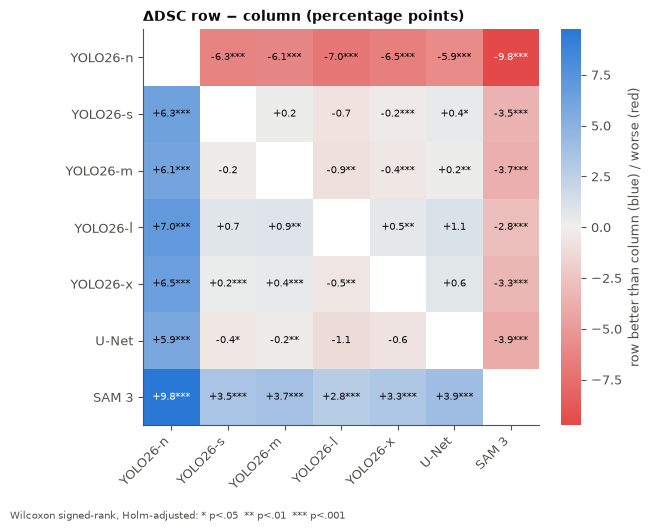

In [11]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
elif art.tests.empty:
    print("⚠️ Paired cross-architecture tests need Phase 5 results from at least two architectures. Skipping cell execution.")
else:
    systems = [s for s in art.sel.system if s in art.per_image]
    fig = agg.fig_pairwise_matrix(art.tests, systems, "dsc", save=art.save_fig)
    plt.show()
    for m in ("jsi", "biou", "hd95"):   # the other metrics: same layout, saved for the supplementary material
        plt.close(agg.fig_pairwise_matrix(art.tests, systems, m, save=art.save_fig))

## Figure 5 — Boundary metrics (Metrics Reloaded)

Boundary IoU (band = 2 % of the image diagonal), NSD (tolerance = 1 % of the diagonal) and HD95, per-image mean with
bootstrap 95 % CI. Overlap scores are dominated by the lesion interior; these measure contour adherence.

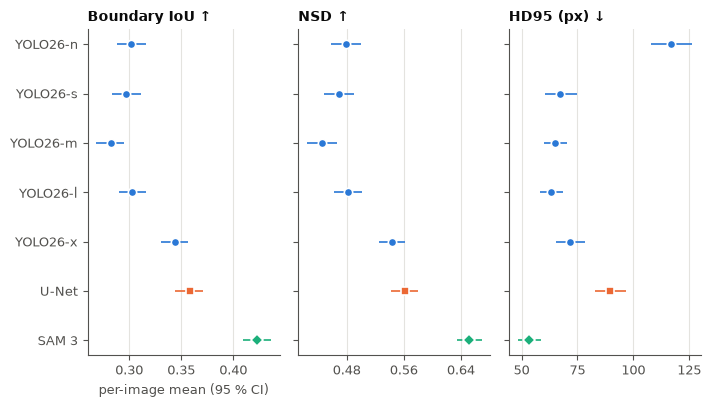

,metric,A,B,delta,ci95_low,ci95_high,p_holm
42,biou,YOLO26-n,YOLO26-s,0.0053,-0.0068,0.0169,0.8263
43,biou,YOLO26-n,YOLO26-m,0.0198,0.0067,0.0325,0.0015
44,biou,YOLO26-n,YOLO26-l,-0.0009,-0.0140,0.0120,0.8263
45,biou,YOLO26-n,YOLO26-x,-0.0416,-0.0525,-0.0319,0.0000
46,biou,YOLO26-n,U-Net,-0.0562,-0.0670,-0.0451,0.0000
...,...,...,...,...,...,...,...
100,hd95,YOLO26-l,U-Net,-26.4387,-32.3698,-20.7093,0.0000
101,hd95,YOLO26-l,SAM 3,9.8661,5.2537,14.2965,0.0000
102,hd95,YOLO26-x,U-Net,-18.0649,-24.9947,-11.5962,0.0784
103,hd95,YOLO26-x,SAM 3,18.2400,13.4890,23.2823,0.0000


In [12]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
elif art.tests.empty:
    print("⚠️ Paired cross-architecture tests need Phase 5 results from at least two architectures. Skipping cell execution.")
else:
    fig = agg.fig_boundary_metrics(art.sel, save=art.save_fig)
    plt.show()
    display(art.tests[art.tests.metric.isin(["biou", "nsd", "hd95"])][["metric", "A", "B", "delta", "ci95_low", "ci95_high", "p_holm"]].round(4))

## Figure 6 — Peak GPU memory

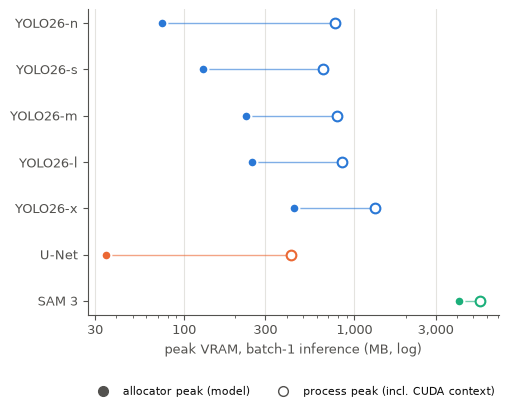

In [13]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig = agg.fig_memory(art.sel, save=art.save_fig)
    plt.show()

## Table 3 — Effect of HPO (Optimized − Baseline)

In [14]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.tables["hpo_gain"])

,System,n,ΔDSC,p (DSC),ΔJSI,p (JSI),ΔBoundary IoU,p (Boundary IoU),ΔNSD,p (NSD),ΔHD95 (px),p (HD95 (px))
0,YOLO26-n,1000,"-0.0637 [-0.0768, -0.0511]",<0.001,"-0.0635 [-0.0771, -0.0502]",<0.001,"0.0053 [-0.0074, 0.0173]",0.075,"-0.0005 [-0.0182, 0.0186]",0.527,"48.8 [39.9, 57.7]",<0.001
1,YOLO26-s,1000,"-0.0062 [-0.0130, 0.0008]",0.003,"-0.0086 [-0.0161, -0.0007]",0.003,"-0.0252 [-0.0344, -0.0160]",<0.001,"-0.0497 [-0.0650, -0.0347]",<0.001,"-3.4 [-8.9, 2.2]",0.043
2,YOLO26-m,1000,"-0.0052 [-0.0117, 0.0009]",<0.001,"-0.0076 [-0.0149, -0.0003]",<0.001,"-0.0203 [-0.0297, -0.0104]",<0.001,"-0.0339 [-0.0491, -0.0187]",<0.001,"-2.1 [-6.1, 1.7]",0.174
3,YOLO26-l,1000,"0.0052 [-0.0001, 0.0112]",<0.001,"0.0024 [-0.0038, 0.0091]",<0.001,"-0.0154 [-0.0250, -0.0063]",<0.001,"-0.0239 [-0.0393, -0.0091]",<0.001,"-6.1 [-10.9, -1.9]",0.007
4,YOLO26-x,1000,"0.0049 [-0.0026, 0.0123]",<0.001,"0.0108 [0.0023, 0.0191]",<0.001,"0.0514 [0.0406, 0.0631]",<0.001,"0.0853 [0.0688, 0.1019]",<0.001,"4.3 [-0.4, 9.2]",0.503
5,U-Net,1000,"0.0014 [-0.0057, 0.0091]",0.007,"-0.0023 [-0.0097, 0.0060]",0.004,"-0.0195 [-0.0274, -0.0121]",<0.001,"-0.0291 [-0.0401, -0.0181]",<0.001,"7.0 [1.4, 12.5]",<0.001
6,SAM 3,1000,"-0.0044 [-0.0096, 0.0001]",0.960,"-0.0057 [-0.0114, -0.0004]",0.985,"-0.0024 [-0.0089, 0.0041]",0.402,"-0.0032 [-0.0116, 0.0049]",0.900,"4.1 [0.7, 8.2]",0.800


## Table 4 — FP16 vs. FP32

In [15]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.tables["precision"].round(4))

,System,DSC FP32,DSC FP16,ΔDSC (FP16−FP32),Fwd FP32 (ms),Fwd FP16 (ms),Speed-up (fwd),E2E FP32 (ms),E2E FP16 (ms),Speed-up (E2E),VRAM FP32 (MB),VRAM FP16 (MB)
0,YOLO26-n,0.8121,0.8123,0.0002,8.2616,8.8939,0.9289,12.4525,13.5485,0.9191,73.6958,56.0464
1,YOLO26-s,0.8747,0.8753,0.0007,8.7792,9.1817,0.9562,11.6016,12.4189,0.9342,129.1377,86.5117
2,YOLO26-m,0.8728,0.8728,0.0000,12.5368,10.4141,1.2038,13.2996,13.2759,1.0018,232.3931,155.2363
3,YOLO26-l,0.8819,0.8819,-0.0000,14.9381,14.4113,1.0366,16.6079,17.3870,0.9552,249.1689,188.6382
4,YOLO26-x,0.8771,0.8767,-0.0004,27.1688,14.9740,1.8144,24.5531,19.1094,1.2849,439.0493,268.5752
5,U-Net,0.8706,0.8707,0.0001,1.5319,1.8622,0.8226,4.7955,5.1680,0.9279,34.9067,21.2720
6,SAM 3,0.9096,0.9096,0.0000,600.8525,195.5185,3.0731,607.1530,201.9139,3.0070,4105.5283,3882.1367


## Table 6 — Cross-validation vs. test

In [16]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    display(art.tables["cv_vs_test"])

,System,CV DSC (mean ± SD),CV JSI (mean ± SD),"Test DSC, Baseline","Test JSI, Baseline"
0,YOLO26-n,0.900 ± 0.006,0.834 ± 0.008,"0.876 [0.867, 0.884]","0.799 [0.789, 0.808]"
1,YOLO26-s,0.899 ± 0.006,0.833 ± 0.008,"0.881 [0.872, 0.889]","0.806 [0.796, 0.816]"
2,YOLO26-m,0.901 ± 0.004,0.835 ± 0.005,"0.878 [0.870, 0.886]","0.801 [0.792, 0.811]"
3,YOLO26-l,0.900 ± 0.006,0.835 ± 0.008,"0.877 [0.867, 0.886]","0.804 [0.793, 0.814]"
4,YOLO26-x,0.900 ± 0.004,0.834 ± 0.006,"0.872 [0.864, 0.880]","0.793 [0.783, 0.803]"
5,U-Net,0.883 ± 0.007,0.811 ± 0.009,"0.869 [0.859, 0.879]","0.797 [0.785, 0.809]"
6,SAM 3,0.908 ± 0.004,0.846 ± 0.005,"0.914 [0.907, 0.920]","0.855 [0.846, 0.863]"


## Key numbers for the Results section

Generated from the tables above — copy, then rephrase. Every number is traceable to `sandbox_models_analysis/exports/repo_notebook_04/`.

In [17]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    for line in agg.key_numbers(art):
        print("•", line)
    print("\nFiles:")
    for f in sorted((art.out / "tables").glob("*.tex")) + sorted((art.out / "figures").glob("*.pdf")):
        print("  ", f.relative_to(art.out))

• Highest test DSC: SAM 3 with 0.910 [0.902, 0.916] (JSI 0.849 [0.840, 0.857]).
• Fastest network: U-Net, forward median 1.53 ms (P95 1.63 ms, 642 FPS), end-to-end median 4.80 ms (P95 4.89 ms).
• Meeting the 30-FPS real-time criterion (E2E P95 ≤ 33.3 ms, FP32): YOLO26-n, YOLO26-s, YOLO26-m, YOLO26-l, YOLO26-x, U-Net.
• SAM 3 vs. the most accurate lightweight model (YOLO26-l): ΔDSC = +0.0277 [+0.0210, +0.0347], Holm-adjusted p < 0.001, rank-biserial r = +0.54.
• Cost ratio SAM 3 / YOLO26-l: parameters ×30, GFLOPs ×43, forward latency ×40, end-to-end latency ×37, peak VRAM (allocator) ×16.
• Friedman test across the 7 systems (DSC): χ² = 511.3, p < 0.001, Kendall's W = 0.085.

Files:
   tables/table1_accuracy.tex
   tables/table2_efficiency.tex
   tables/table3_hpo_gain.tex
   tables/table4_fp16.tex
   tables/table5_training_cost.tex
   tables/table6_cv_vs_test.tex
   tables/table7_pairwise_dsc.tex
   figures/fig0_phase1_side_by_side.pdf
   figures/fig1_accuracy_vs_efficiency.pdf
   figu

## Reading notes (keep these caveats in the thesis)

* **Resolution.** Every model is scored at the dataset resolution against the same official masks, but each runs at
  its own native input (U-Net 256, YOLO26 640, SAM 3 1008 px). Part of the accuracy and cost differences is the input
  resolution — state it.
* **GFLOPs** are reported at the native input; the U-Net's GFLOPs at 640 px are in `data/systems_selected.csv`
  (`gflops_640`) for a resolution-matched comparison. thop (CNNs) and `FlopCounterMode` (SAM 3) agree on convolutions
  and linear layers; only the latter counts attention products.
* **Budgets.** YOLO26 and U-Net: 120 epochs, HPO 30 × 30; SAM 3: 30 epochs, HPO 10 × 10 (compute). None uses early
  stopping. See `methodology_notes.md`.
* **Latency** depends on the GPU, driver and software stack (recorded in each efficiency JSON); quote the GPU model
  with every number, and never the per-image `infer_ms` column of Phase 5a (a by-product, not a benchmark).
* **Variant.** The comparison uses the variant fixed in advance (`DEPLOY_VARIANT`); Table 3 shows whether HPO helped.